# Atividade 01c - Investigação do baseline de inferência

<table style="margin-left: 0; margin-right: auto; text-align: left;">
  <thead>
    <tr>
      <th>Item</th>
      <th>Identificação</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Revisão-base</td>
      <td><a href="https://github.com/leandrocsiqueira/ai-coding-tokenomics/commit/3a1be993041ed75f77f26f23b0cacf0aff507d30">3a1be99</a></td>
    </tr>
    <tr>
      <td>Implementação de referência</td>
      <td><a href="https://github.com/leandrocsiqueira/ai-coding-tokenomics/blob/3a1be993041ed75f77f26f23b0cacf0aff507d30/src/03_cpu_gpu_baseline.py">src/03_cpu_gpu_baseline.py</a></td>
    </tr>
    <tr>
      <td>Métricas originais coletadas</td>
      <td><a href="https://github.com/leandrocsiqueira/ai-coding-tokenomics/blob/3a1be993041ed75f77f26f23b0cacf0aff507d30/results/cpu_gpu_baseline.csv">results/cpu_gpu_baseline.csv</a></td>
    </tr>
    <tr>
      <td>Backup das métricas originais</td>
      <td><a href="https://github.com/leandrocsiqueira/ai-coding-tokenomics/blob/c18938c2d0aa70f6394e58b52f73a633c7f8f5b6/results/archive/cpu_gpu_baseline_pre_revision_2026-10-30.csv">results/archive/cpu_gpu_baseline_pre_revision_2026-10-30.csv</a></td>
    </tr>
    <tr>
      <td>Dataset e carregador da investigação</td>
      <td><a href="dataset/consumo_cartao_credito_01c.json">dataset</a> | <a href="dataset/loader_dataset.py">carregador</a></td>
    </tr>
  </tbody>
</table>


## Introdução

Este notebook investiga a **baseline de inferência** implementada em `src/03_cpu_gpu_baseline.py`, tomando como referência o [commit de 05/10/2026](https://github.com/leandrocsiqueira/ai-coding-tokenomics/blob/3a1be993041ed75f77f26f23b0cacf0aff507d30/src/03_cpu_gpu_baseline.py). O objetivo é compreender seu funcionamento, interpretar resultados e registrar evidências que permitam fundamentar decisões futuras.

Os objetivos das oito seções que compõe este estudo são descritas a seguir:

➤ **Seções 1 a 4:** tratam do fluxo de inferência, dos parâmetros de geração, do aquecimento, da cronometragem e do carregamento do [LLM](https://www.ibm.com/br-pt/think/topics/large-language-models).

➤ **Seções 5 e 6:** examinam o uso de memória e as medidas de desempenho.

➤ **Seções 7 e 8:** abrangem a preservação de novas execuções e a análise de capacidade e custo para um lote de 10 mil clientes.

Cada seção possui uma pergunta técnica a ser investigada, bem como a explicação correspondente, as referências usadas e verificações realizadas e os resultados observados. Também são registradas, quando aplicável, as expectativas estabelecidas antes das verificações experimentais, os resultados observados, interpretações técnicas, decisões tomadas e eventuais dúvidas que ainda permaneçam em aberto.

### Registro do Ambiente

In [17]:
from datetime import datetime
from importlib.metadata import PackageNotFoundError, version
import platform

from IPython.display import display
import pandas as pd
import psutil
import torch

try:
    transformers = version("transformers")
except PackageNotFoundError:
    transformers = "Não instalado"

try:
    accelerate = version("accelerate")
except PackageNotFoundError:
    accelerate = "Não instalado"

try:
    pandas = version("pandas")
except PackageNotFoundError:
    pandas = "Não instalado"

cuda_disponivel = torch.cuda.is_available()
indice_gpu = None
gpu = None

if cuda_disponivel:
    try:
        indice_gpu = torch.cuda.current_device()
        gpu = torch.cuda.get_device_properties(indice_gpu)
    except RuntimeError as erro:
        indice_gpu = None
        print(f"Aviso: não foi possível consultar a GPU CUDA: {erro}")

ambiente = {
    "Sistema operacional": platform.freedesktop_os_release()["PRETTY_NAME"],
    "Arquitetura": platform.machine(),
    "Total de RAM (GiB)": f"{psutil.virtual_memory().total / 1024**3:.2f}",
    "Python": platform.python_version(),
    "PyTorch": torch.__version__,
    "Transformers": transformers,
    "Accelerate": accelerate,
    "Pandas": pd.__version__,
    "PyTorch com suporte a CUDA?": "Sim" if cuda_disponivel else "Não",
    "Versão da CUDA disponível no PyTorch": torch.version.cuda or "Sem suporte",
    "Índice da GPU selecionada": indice_gpu if indice_gpu is not None else "—",
    "Identificador da GPU": gpu.name if gpu is not None else "—",
    "Total de VRAM da GPU (GiB)": f"{gpu.total_memory / 1024**3:.2f}" if gpu else "—",
}

tabela = pd.DataFrame(ambiente.items(), columns=["Especificação", "Valor"])

display(
    tabela.style.hide(axis="index").set_table_styles([
        {
            "selector": "th.col_heading, td",
            "props": [
                ("text-align", "left"),
                ("padding", "6px 12px"),
                ("white-space", "normal"),
                ("overflow-wrap", "anywhere"),
            ],
        },
    ])
)

print("Data e hora do registro:", datetime.now().strftime("%d/%m/%Y %H:%M:%S"), "\n")

Especificação,Valor
Sistema operacional,Ubuntu 24.04.5 LTS
Arquitetura,x86_64
Total de RAM (GiB),31.03
Python,3.12.3
PyTorch,2.14.1+cu130
Transformers,5.20.2
Accelerate,1.15.0
Pandas,3.1.0
PyTorch com suporte a CUDA?,Sim
Versão da CUDA disponível no PyTorch,13.0


Data e hora do registro: 06/11/2026 13:17:10 



## 1. Inferência de LLM e Diagramas de Fluxo

Esta seção combina a explicação conceitual da **inferência** em [modelos autoregressivos](https://deepgenerativemodels.github.io/notes/autoregressive/), a leitura dos **diagramas de fluxo** da [revisão-base](https://github.com/leandrocsiqueira/ai-coding-tokenomics/blob/3a1be993041ed75f77f26f23b0cacf0aff507d30/src/03_cpu_gpu_baseline.py) e a verificação experimental da passagem de texto para tensores, da geração de novos IDs e de sua posterior decodificação. O experimento usa o mesmo modelo e o *prompt*, embora não se trate de medições de desempenho.

### Investigação

Como o [script da revisão base](https://github.com/leandrocsiqueira/ai-coding-tokenomics/blob/3a1be993041ed75f77f26f23b0cacf0aff507d30/src/03_cpu_gpu_baseline.py) organiza e executa o **processo de inferência** e quais dados são recebidos e retornados pelo método [`inference_model.generate()`](https://github.com/huggingface/transformers/blob/v5.20.2/src/transformers/generation/utils.py#L2568)?

### Revisão

**Inferência** refere-se ao processo de utilizar um modelo treinado para processar uma entrada e produzir uma saída. No contexto deste estudo, esse processo pode ser estruturado conceitualmente em 3 etapas básicas:

- Pré-processamento: Tokenização e a preparação da entrada.
- Geração: previsão e seleção de novos tokens.
- Pós-processamento: Decodificação dos identificadores numéricos em texto.

No caso de um modelo autorregressivo, como o [Qwen2.5-0.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct), a geração é feita de forma progressiva: a previsão do próximo [token](https://blogs.nvidia.com/blog/ai-tokens-explained/) se dá com base na sequência disponível, formada pelos tokens de entrada e por aqueles já previstos.

Na etapa de pré-processamento, a entrada é segmentada em tokens pelo [**Tokenizador**](https://huggingface.co/docs/transformers/main_classes/tokenizer), onde cada um é representado por um identificador numérico conforme o mapeamento definido no [vocabulário](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct/blob/main/vocab.json) que por ele é utilizado.

<figure style="width: 50%;">

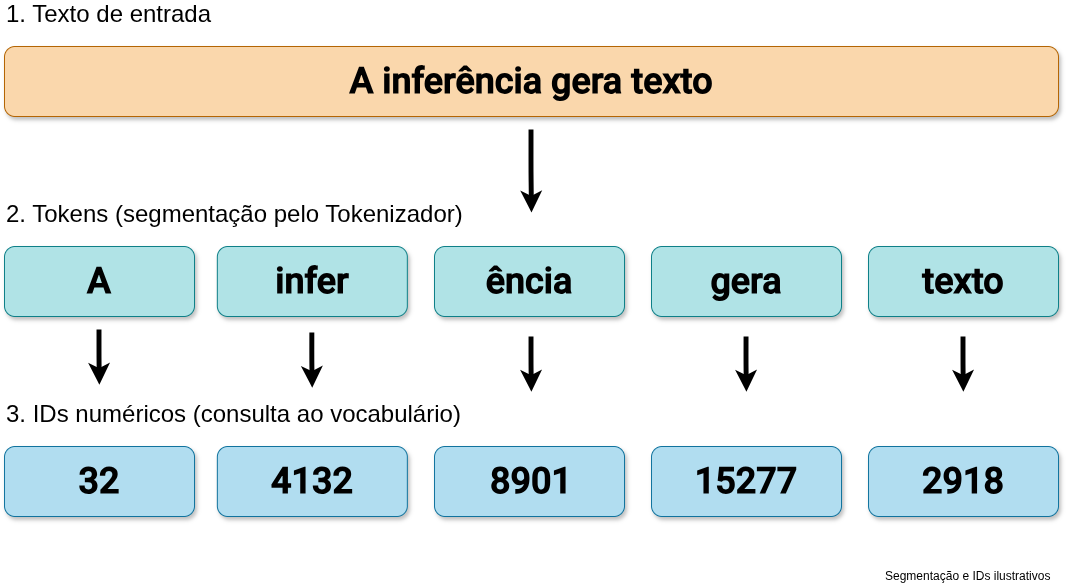

</figure>

Na etapa da geração, após receber e processar a sequência de identificadores dos tokens, o modelo calcula uma pontuação para cada token de seu vocabulário como sendo candidatos à próxima posição. Conforme a estratégia de geração adotada, o próximo token é selecionado e seu identificador é adicionado à sequência existente.A geração se repete até que uma condição de parada seja atingida, como o limite definido para novos tokens.

<figure style="width: 50%;">

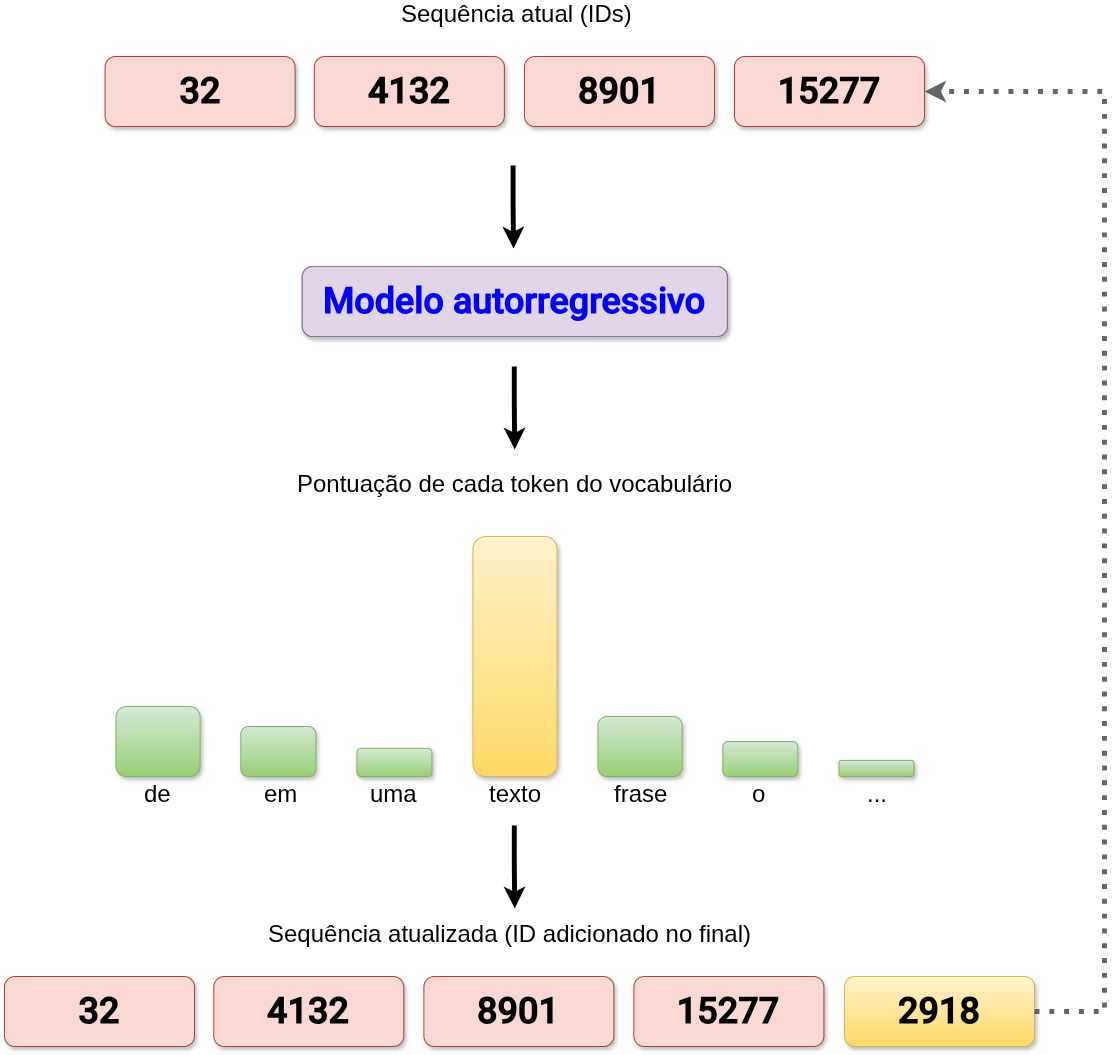

</figure>

No pós-processamento, a sequência de identificadores pode ser decodificada em texto pelo Tokenizador para serem apresentados como resposta. Dependendo de quais identificadores sejam submetidos à decodificação, o texto obtido poderá incluir a entrada ou somente a geração produzida pelo modelo.

### Fluxogramas

O fluxograma a seguir apresenta, de forma simplificada, o fluxo de execução da [revisão-base](https://github.com/leandrocsiqueira/ai-coding-tokenomics/blob/3a1be993041ed75f77f26f23b0cacf0aff507d30/src/03_cpu_gpu_baseline.py), onde é possível identificar que o Tokenizador é carregado fora da função `main()`, independentemente de o arquivo ser executado diretamente ou importado como módulo. Isso possibilita reutilizar a mesma instância do Tokenizador nas diferentes execuções da função `run_inference()`, evitando recarregamentos desnecessários.

<figure style="width: 50%;">

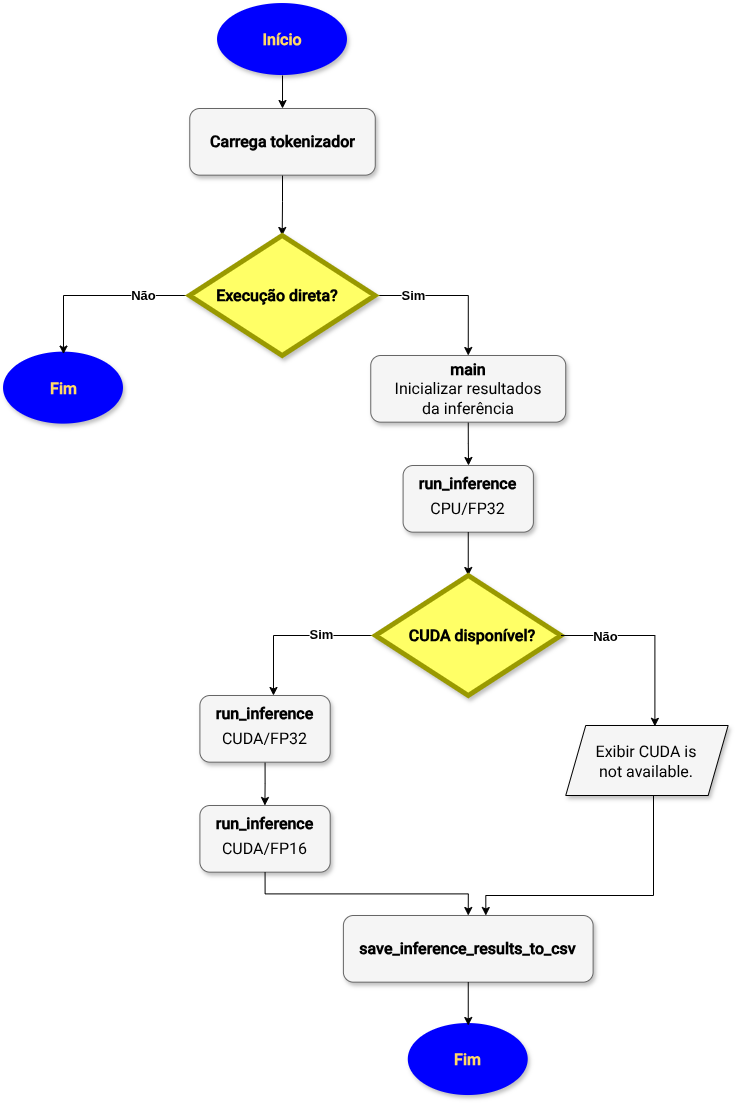

</figure>

A função `main()` inicializa a estrutura de armazenamento dos resultados e executa a inferência em CPU com precisão numérica FP32. Em seguida, verifica a disponibilidade de [CUDA](https://blog.nvidia.com.br/blog/o-que-e-cuda/) para determinar se as inferências em GPU com as precisões FP32 e FP16 também serão realizadas. Caso não esteja disponível, uma mensagem é exibida. Ao final, os resultados obtidos são salvos em um arquivo CSV.

**Notas:** 

1. A chamada automática de `main()` ocorre somente na execução direta do script.
2. A inferência em CPU é sempre executada.

O próximo diagrama detalha o fluxo de execução da função `run_inference()`, responsável por coordenar o processo de inferência e acionar funções auxiliares para a execução de tarefas específicas.

-- ATUALIZAR DIAGRAMA DA FUNÇÃO RUN_INFERENCE() --

Caso se trata de uma configuração de inferência que use GPU, a função executa `prepare_cuda_memory_for_inference` passando-lhe uma referência para o dispositivo de execução como argumento, de maneira que ela realize a limpeza do cache CUDA e reinicie as estatísticas de pico de memória antes do carregamento do modelo.

<figure style="width: 50%;">

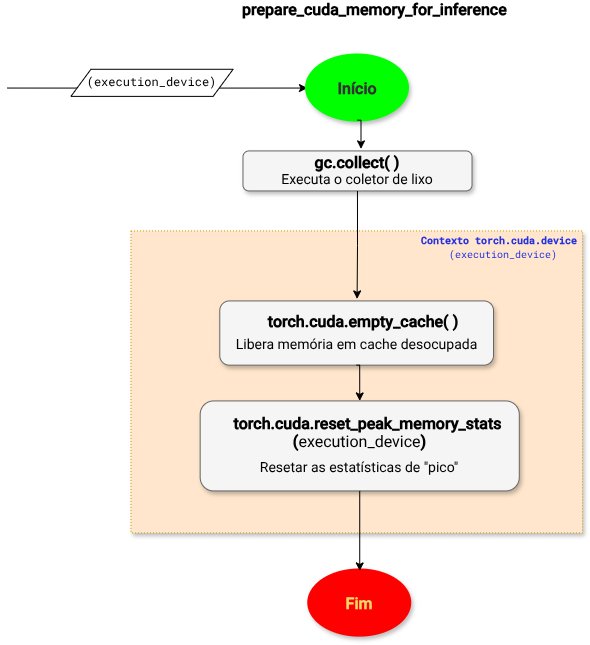

</figure>

Em seguida, `run_inference` prepara o ambiente de execução, carrega o modelo, configura o dispositivo e a precisão numérica e realiza a tokenização do prompt. Depois, executa `pre_inference_warmup()` para que esta realize a inferência preliminar sem medição de tempo e com descarte dos tokens gerados.

<figure style="width: 70%;">
    
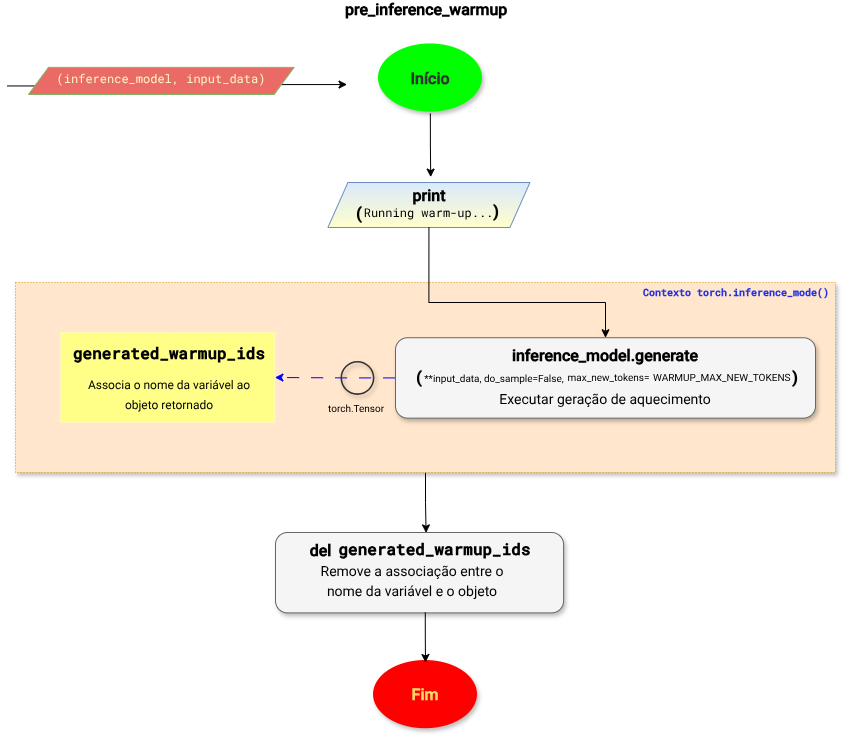

</figure>

Concluída a operação, `run_inference()` executa `execute_inference_with_timing()` para realizar a geração com medição de tempo, que também sincroniza CUDA quando configuração de inferência usar GPU.

-- DIAGRAMA DA FUNÇÃO EXECUTE_INFERENCE_WITH_TIMING() --

Assumindo novamente o controle e calcular as métricas de desempenho e consumo de memória, `run_inference`  executa `collect_gpu_memory_metrics()` nos casos em que a configuração use GPU.

<figure style="width: 70%;">

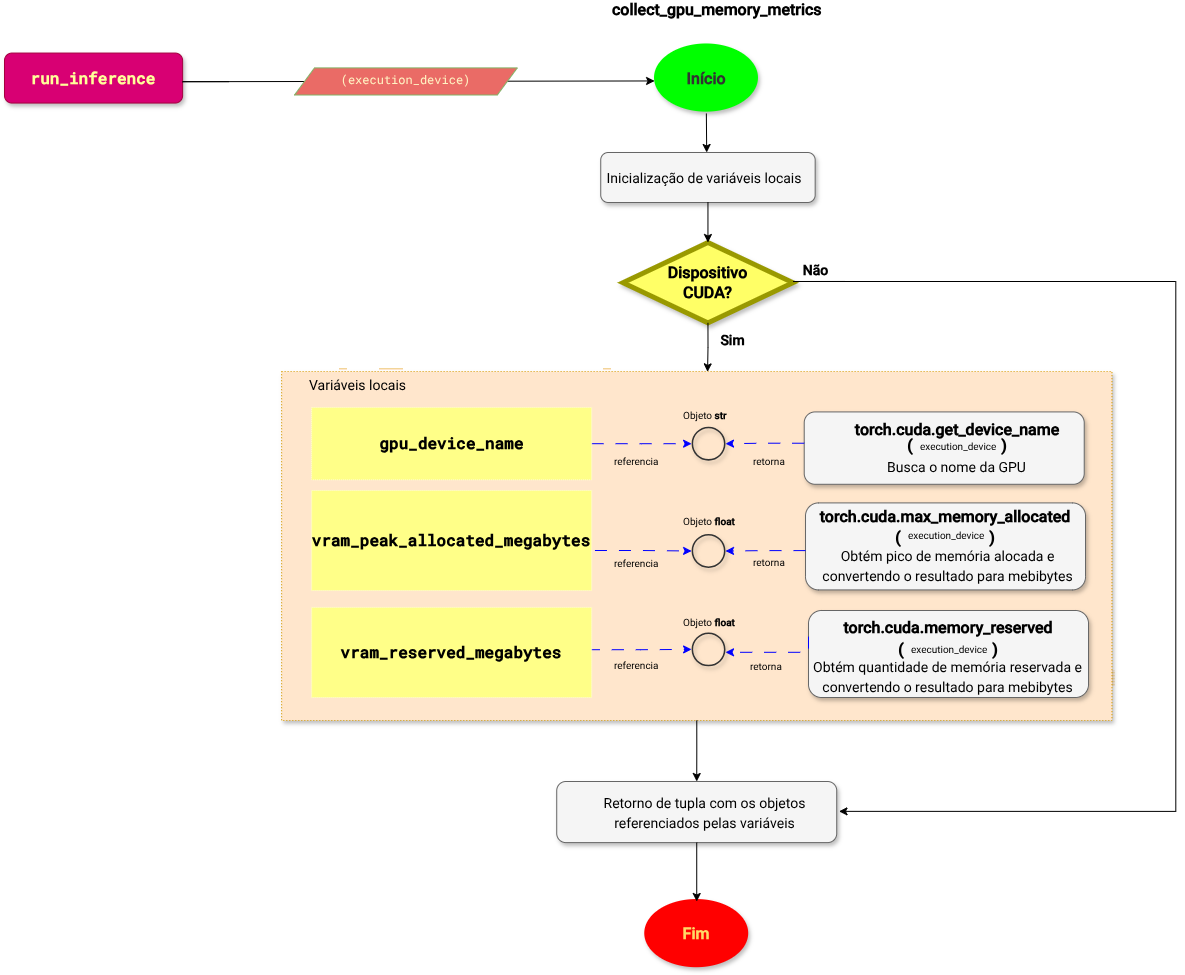

</figure>

Após `run_inference()` decodificar os IDs gerados, ela executa `print_inference_results()` para apresentar os resultados no terminal.

-- DIAGRAMA DA FUNÇÃO PRINT_INFERENCE_RESULTS() --

Por fim, além de `run_inference` retornar as métricas para `main`, ela também limpa as referências de memória usadas pelas variáveis, executa o coletor de lixo do Python e realiza a limpeza do cache CUDA, caso a configuração de inferência use GPU.

Para que as métricas sejam salvas em arquivo CSV, `main` executa `save_inference_results_to_csv` e o script é encerrado.

-- DIAGRAMA DA FUNÇÃO SAVE_INFERENCE_RESULTS_TO_CSV --

### Geração de Sequências de IDs de Tokens

O código a seguir reproduz, de forma isolada, a chamada ao método [generate()](https://github.com/huggingface/transformers/blob/v5.20.2/src/transformers/generation/utils.py?#L2568-L2584) conforme ele é usado no script de referência.

O objetivo é examinar os dados fornecidos ao modelo e os resultados produzidos pela geração.

In [8]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_IDENTIFIER = "Qwen/Qwen2.5-0.5B-Instruct"
PROMPT = "Explain in two sentences what tokenization is in language models."
MAX_NEW_TOKENS = 50
execution_device = torch.device("cpu")

tokenizer = AutoTokenizer.from_pretrained(MODEL_IDENTIFIER)
    
inference_model = AutoModelForCausalLM.from_pretrained(
    MODEL_IDENTIFIER,
    dtype=torch.float32).to(execution_device).eval()

input_data = tokenizer(PROMPT, return_tensors="pt",).to(execution_device)

input_token_count = input_data["input_ids"].shape[-1]

print("\n=== ENTRADA DE generate() ===")

print(f"\nPrompt: {PROMPT}\n")

for name, tensor in input_data.items():
    print(f"{name}:")
    print(f"  Shape: {tuple(tensor.shape)}")
    print(f"  Dtype: {tensor.dtype}")
    print(f"  Device: {tensor.device}")
    print(f"  Valores: {tensor[0].tolist()}\n")

print("Parâmetros usados na geração:")

print("  do_sample: False")
print(f"  max_new_tokens: {MAX_NEW_TOKENS}")

with torch.inference_mode():
    generated_ids = inference_model.generate(
        **input_data,
        do_sample=False,
        max_new_tokens=MAX_NEW_TOKENS
    )

new_token_ids = generated_ids[:, input_token_count:]

print("\n=== SAÍDA DE generate() ===\n")

print(f"Shape: {tuple(generated_ids.shape)}")
print(f"Dtype: {generated_ids.dtype}")
print(f"Device: {generated_ids.device}")

print(f"\nSequência completa de IDs:\n{generated_ids[0].tolist()}")

print(f"\nIDs dos novos tokens:\n{new_token_ids[0].tolist()}")

print("\n=== VERIFICAÇÃO ===")

print(f"Tokens de entrada: {input_token_count}")
print(f"Tokens novos gerados: {new_token_ids.shape[-1]}")
print(f"Tokens na sequência completa: {generated_ids.shape[-1]}")

prompt_preserved = torch.equal(
    generated_ids[:, :input_token_count],
    input_data["input_ids"],
)

print("\nIDs do prompt preservados na saída:", prompt_preserved, "\n")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]


=== ENTRADA DE generate() ===

Prompt: Explain in two sentences what tokenization is in language models.

input_ids:
  Shape: (1, 13)
  Dtype: torch.int64
  Device: cpu
  Valores: [840, 20772, 304, 1378, 22870, 1128, 3950, 2022, 374, 304, 4128, 4119, 13]

attention_mask:
  Shape: (1, 13)
  Dtype: torch.int64
  Device: cpu
  Valores: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Parâmetros usados na geração:
  do_sample: False
  max_new_tokens: 50

=== SAÍDA DE generate() ===

Shape: (1, 63)
Dtype: torch.int64
Device: cpu

Sequência completa de IDs:
[840, 20772, 304, 1378, 22870, 1128, 3950, 2022, 374, 304, 4128, 4119, 13, 9660, 2022, 374, 279, 1882, 315, 14719, 1495, 264, 8500, 315, 4244, 1119, 3842, 11211, 11, 1741, 438, 11931, 323, 61503, 15423, 13, 1096, 6147, 369, 8661, 8692, 323, 6358, 315, 1467, 821, 553, 17592, 11980, 323, 24588, 22414, 8153, 2878, 432, 13, 3216, 14719, 705, 1293, 9069, 315, 5766]

IDs dos novos tokens:
[9660, 2022, 374, 279, 1882, 315, 14719, 1495, 264, 8500, 315, 

A seção de entrada mostra como o texto do *prompt* foi convertido pelo Tokenizador antes de ser enviado ao modelo. A frase foi representada por 13 tokens, identificados pelos números presentes em `input_ids`. Esses números não são palavras, mas IDs de tokens no vocabulário do Tokenizador.

O formato `(1, 13)` indica que o lote (*batch*) contém uma única sequência, composta por 13 tokens. O tipo `torch.int64` é adequado para IDs de tokens; `Device: cpu` confirma que os tensores exibidos estão na CPU, onde o modelo também se encontra.

A `attention_mask` também possui formato `(1, 13)` e contém apenas valores iguais a 1. Isso indica que todas as 13 posições correspondem a tokens válidos da sequência de entrada, sem posições de preenchimento (*padding*). Se houvesse preenchimento, normalmente essas posições seriam marcadas com 0.

Na geração, `do_sample=False` desativa a amostragem aleatória. Como a configuração usada não emprega busca em feixe (`num_beams=1`), a seleção é gulosa (*greedy decoding*): neste caso, a cada etapa, o modelo escolhe o token com maior pontuação **após quaisquer ajustes aplicados aos logits**. Já `max_new_tokens=50` estabelece um limite de 50 tokens novos. Neste resultado, foram produzidos exatamente 50 tokens, atingindo a quantidade máxima configurada.

A saída apresenta formato `(1, 63)` porque reúne os 13 tokens originais com os 50 novos tokens: 13 + 50 = 63. Assim como na entrada, os IDs são inteiros de 64 bits e permanecem na CPU. A "Sequência completa de IDs" contém primeiro os IDs do *prompt* e, logo depois, os IDs produzidos pelo modelo. Já a seção "IDs dos novos tokens" seleciona apenas a continuação, desconsiderando os 13 tokens iniciais.

A verificação final confirma essa composição: são 13 tokens de entrada, 50 tokens novos e 63 tokens no total. O resultado `IDs do prompt preservados na saída: True` demonstra que os IDs originais do *prompt* foram mantidos no início da sequência retornada, como esperado para esse modelo causal.

Por fim, a saída examinada contém apenas IDs numéricos, e não o texto da resposta. Para visualizar a continuação em linguagem natural, a célula seguinte utiliza `tokenizer.decode(new_token_ids[0])`. **A escolha dos IDs ocorre durante a geração; a conversão posterior desses IDs em texto não muda os tokens selecionados.** A próxima seção investiga precisamente uma dessas decisões: como o próximo token é escolhido quando `do_sample` está desativado ou ativado.

In [3]:
tokenizer.decode(new_token_ids[0])

' Tokenization is the process of breaking down a sequence of words into individual tokens, such as letters and punctuation marks. This allows for easier processing and analysis of text data by removing noise and identifying meaningful units within it. By breaking up long strings of characters'

#### Questão levantada

Uma questão que levante durante o experimento foi a seguinte: no carregamento do modelo, foi especificado o tipo de dado `torch.float32` por meio do argumento `dtype`. Entretanto, ao examinar os tensores de entrada e saída de `inference_model.generate()`, observou-se que todos apresentaram o tipo `torch.int64`. Por que isso acontece? Qual é a diferença entre o tipo de dado utilizado para representar os parâmetros do modelo e aquele utilizado para representar os IDs dos tokens? Como esses diferentes tipos de dados participam do processo de inferência?

#### Lição aprendida

Isso aconteceu porque essas configurações são utilizados para representar tipos diferentes de dados dentro do processo de inferência. O argumento `dtype=torch.float32` determina que os parâmetros de ponto flutuante do modelo sejam carregados em precisão de 32 bits, incluindo, por exemplo, pesos das camadas e das matrizes de embeddings. Entretanto, ele não determina o tipo dos IDs dos tokens, que representam índices inteiros do vocabulário.

Quando o modelo recebe `input_ids`, a camada de embeddings utiliza esses índices inteiros para consultar vetores numéricos aprendidos. Esses vetores são representados em ponto flutuante, de acordo com a precisão dos pesos do modelo.

Após os cálculos, o modelo produz os *logits*, que representam pontuações para os possíveis próximos tokens. A estratégia de geração usa essas pontuações para selecionar ou amostrar o próximo token e retorna seu ID inteiro, não o valor de ponto flutuante utilizado internamente. Isso fica claro no código a seguir:

In [11]:
print("\nTipo dos pesos:", next(inference_model.parameters()).dtype)
print("Tipo dos IDs de entrada:", input_data["input_ids"].dtype)

with torch.inference_mode():
    outputs = inference_model(**input_data)

print("Tipo dos logits:", outputs.logits.dtype)
print("Tipo dos IDs gerados:", generated_ids.dtype, "\n")


Tipo dos pesos: torch.float32
Tipo dos IDs de entrada: torch.int64
Tipo dos logits: torch.float32
Tipo dos IDs gerados: torch.int64 



## 2. Decisões sobre a Geração

### O efeito do parâmetro `do_sample`

No experimento anterior, `generate()` recebeu os IDs de 13 tokens de entrada e retornou uma sequência de 63 IDs, dos quais 50 correspondiam à continuação gerada. A decodificação permitiu ler essa continuação como texto. Resta examinar **como o modelo escolhe cada novo ID**. No [baseline](https://github.com/leandrocsiqueira/ai-coding-tokenomics/blob/3a1be993041ed75f77f26f23b0cacf0aff507d30/src/03_cpu_gpu_baseline.py), a chamada utiliza explicitamente `do_sample=False` e `max_new_tokens=50` tanto no aquecimento quanto na geração medida.

A cada passo da geração autorregressiva, o modelo produz *logits*, ou seja, pontuações não normalizadas associadas aos tokens candidatos do vocabulário. Antes da seleção, essas pontuações podem sofrer ajustes, como uma penalidade de repetição. A estratégia de geração determina como se obtém o próximo ID a partir das pontuações resultantes. Com `num_beams=1`, que é a configuração deste experimento, distinguem-se dois procedimentos:

🟣 **`do_sample=False` - decodificação gulosa (*greedy decoding*).** A cada passo, é selecionado o token com a maior pontuação ajustada (`argmax`). Não há sorteio. Nas mesmas condições de execução, tende a reproduzir a mesma sequência, mas diferenças numéricas ou de implementação entre ambientes podem afetar o resultado. A estratégia escolhe o token mais bem pontuado **em cada passo**, não necessariamente a sequência completa de maior probabilidade.

🔵 **`do_sample=True` - amostragem probabilística (*multinomial sampling*).** As pontuações ajustadas são transformadas em probabilidades, e o próximo token é sorteado segundo essa distribuição, possivelmente após filtros. Portanto, outros tokens além do mais provável podem ser escolhidos. Execuções com a mesma entrada podem produzir continuações diferentes. Fixar uma semente (*seed*) (*seed*) de aleatoriedade ajuda a reproduzir um sorteio nas mesmas condições, mas não transforma a estratégia em decodificação gulosa.

#### Configurações que também influenciam a escolha

O comportamento de `generate()` não depende apenas de `do_sample`. A [configuração de geração](https://huggingface.co/docs/transformers/v5.20.2/en/main_classes/text_generation#transformers.GenerationConfig) carregada com o modelo fornece valores que não forem substituídos na chamada. O arquivo [`generation_config.json` do Qwen2.5-0.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct/blob/main/generation_config.json) estabelece, na versão examinada, `do_sample=True`, `repetition_penalty=1.1`, `temperature=0.7`, `top_k=20` e `top_p=0.8`. A chamada explícita com `do_sample=False` no baseline **substitui o valor padrão de `do_sample`**, sem anular automaticamente os demais ajustes aplicáveis.

`repetition_penalty=1.1` altera as pontuações de tokens já presentes no contexto e pode influenciar **tanto a seleção gulosa quanto a amostragem**; o valor neutro é `1.0`. Já `temperature=0.7` modifica a concentração da distribuição de probabilidades, `top_k=20` restringe os candidatos aos 20 tokens com maior pontuação e `top_p=0.8` seleciona um subconjunto com massa acumulada de probabilidade de pelo menos 0,8, conforme a ordenação dos candidatos. **Esses três controles são usados na amostragem, mas não na decodificação gulosa.** A combinação de `top_k` e `top_p` pode restringir ainda mais o conjunto de candidatos; ela não determina antecipadamente qual token será sorteado.

O parâmetro `num_beams` também importa: `num_beams=1` permite comparar diretamente *greedy decoding* e amostragem multinomial; valores maiores ativam estratégias de busca em feixe e mudam a interpretação. Já `max_new_tokens=50` controla o **limite** de tokens novos, e não o método de escolha: a geração pode terminar antes, por exemplo, ao produzir um ID de fim de sequência (`eos_token_id`).

Na saída registrada na seção 1, o último ID foi `5766`. A configuração consultada lista `151645` e `151643` como IDs de fim de sequência; portanto, **aquele resultado específico não terminou com um EOS**, mas atingiu o limite de 50 novos tokens. A célula seguinte verifica novamente essa conclusão com os valores carregados no próprio ambiente.

Os dois exemplos abaixo reutilizam `inference_model`, `tokenizer`, `input_data`, `input_token_count` e `MAX_NEW_TOKENS` definidos na seção anterior. A configuração será primeiro inspecionada **em tempo de execução**, pois uma revisão diferente dos arquivos do modelo pode fornecer outros valores. Em seguida, compararemos o texto e os IDs resultantes de cada estratégia, sem utilizar a duração das execuções como benchmark.

In [14]:
generation_config = inference_model.generation_config

print("\n=== CONFIGURAÇÃO DE GERAÇÃO CARREGADA ===")

for parameter_name in (
    "do_sample",
    "num_beams",
    "repetition_penalty",
    "temperature",
    "top_k",
    "top_p",
    "eos_token_id",
):
    print(f"{parameter_name}: {getattr(generation_config, parameter_name)}")

eos_token_ids = generation_config.eos_token_id
if isinstance(eos_token_ids, int):
    eos_token_ids = [eos_token_ids]
elif eos_token_ids is None:
    eos_token_ids = []

last_new_token_id = int(new_token_ids[0, -1].item())
print(f"\nÚltimo ID novo da seção 1: {last_new_token_id}")
print(f"Esse ID é um EOS configurado? {last_new_token_id in eos_token_ids}\n")


=== CONFIGURAÇÃO DE GERAÇÃO CARREGADA ===
do_sample: True
num_beams: None
repetition_penalty: 1.1
temperature: 0.7
top_k: 20
top_p: 0.8
eos_token_id: [151645, 151643]

Último ID novo da seção 1: 5766
Esse ID é um EOS configurado? False



### Exemplo 1 - `do_sample=False`: escolha gulosa

Este exemplo reproduz a estratégia usada pelo baseline: com `num_beams=1` e `do_sample=False`, a escolha do token é feita pelo maior logit ajustado, sem amostragem. Mantemos o mesmo modelo, *prompt*, dispositivo e limite de 50 tokens. O programa compara os IDs retornados com `generated_ids` da seção 1 para verificar se a sequência foi reproduzida nesta execução.

A penalidade de repetição configurada no modelo pode continuar atuando; `temperature`, `top_k` e `top_p` não são empregados como filtros de amostragem nesta estratégia.

In [15]:
with torch.inference_mode():
    greedy_generated_ids = inference_model.generate(
        **input_data,
        do_sample=False,
        num_beams=1,
        max_new_tokens=MAX_NEW_TOKENS,
    )

greedy_new_ids = greedy_generated_ids[:, input_token_count:]
greedy_text = tokenizer.decode(greedy_new_ids[0], skip_special_tokens=True)

print("\n=== EXEMPLO 1: do_sample=False ===")
print(f"Tokens novos: {greedy_new_ids.shape[-1]}")
print(f"IDs gerados: {greedy_new_ids[0].tolist()}")
print(f"Mesmo resultado da seção 1? {torch.equal(greedy_generated_ids, generated_ids)}")
print(f"\nTexto decodificado:\n{greedy_text}\n")


=== EXEMPLO 1: do_sample=False ===
Tokens novos: 50
IDs gerados: [9660, 2022, 374, 279, 1882, 315, 14719, 1495, 264, 8500, 315, 4244, 1119, 3842, 11211, 11, 1741, 438, 11931, 323, 61503, 15423, 13, 1096, 6147, 369, 8661, 8692, 323, 6358, 315, 1467, 821, 553, 17592, 11980, 323, 24588, 22414, 8153, 2878, 432, 13, 3216, 14719, 705, 1293, 9069, 315, 5766]
Mesmo resultado da seção 1? True

Texto decodificado:
 Tokenization is the process of breaking down a sequence of words into individual tokens, such as letters and punctuation marks. This allows for easier processing and analysis of text data by removing noise and identifying meaningful units within it. By breaking up long strings of characters



### Exemplo 2 - `do_sample=True`: amostragem probabilística

Agora o `do_sample` é modificado para `True`, mantendo `num_beams=1`, os mesmos dados de entrada e `max_new_tokens=50`. Os valores de `temperature`, `top_k`, `top_p` e `repetition_penalty` são herdados da configuração carregada do modelo, sem ajustes adicionais no código. Assim, **a mudança experimental explícita entre as chamadas de geração é `do_sample`**; os parâmetros da configuração passam a exercer efeitos distintos, de acordo com a estratégia.

Uma semente de aleatoriedade é fixada antes da primeira geração amostrada para permitir sua reprodução sob condições equivalentes. Uma segunda geração, com *seed*, serve para verificar se o sorteio produz uma continuação diferente. Resultados diferentes são possíveis, mas **não são garantidos** em toda combinação de *seed*, modelo e *prompt*.

In [16]:
# Primeira amostragem: a seed controla o estado do gerador aleatório.
torch.manual_seed(42)

with torch.inference_mode():
    sampled_generated_ids = inference_model.generate(
        **input_data,
        do_sample=True,
        num_beams=1,
        max_new_tokens=MAX_NEW_TOKENS,
    )

sampled_new_ids = sampled_generated_ids[:, input_token_count:]
sampled_text = tokenizer.decode(sampled_new_ids[0], skip_special_tokens=True)

# Segunda amostragem: mesmo modelo e configurações, outra seed
torch.manual_seed(43)

with torch.inference_mode():
    sampled_generated_ids_2 = inference_model.generate(
        **input_data,
        do_sample=True,
        num_beams=1,
        max_new_tokens=MAX_NEW_TOKENS,
    )

sampled_new_ids_2 = sampled_generated_ids_2[:, input_token_count:]
sampled_text_2 = tokenizer.decode(sampled_new_ids_2[0], skip_special_tokens=True)

print("\n=== EXEMPLO 2: do_sample=True ===")
print(f"\nsemente (*seed*) 42 - tokens novos: {sampled_new_ids.shape[-1]}")
print(f"IDs gerados: {sampled_new_ids[0].tolist()}")
print(f"Texto decodificado:\n{sampled_text}")

print(f"\nsemente (*seed*) 43 - tokens novos: {sampled_new_ids_2.shape[-1]}")
print(f"IDs gerados: {sampled_new_ids_2[0].tolist()}")
print(f"Texto decodificado:\n{sampled_text_2}")

print("\n=== COMPARAÇÃO DAS ESTRATÉGIAS ===")
print(f"Amostragem (semente (*seed*) 42) igual à geração gulosa? {torch.equal(sampled_generated_ids, greedy_generated_ids)}")
print(f"Amostragens com semente (*seed*)s diferentes iguais? {torch.equal(sampled_generated_ids, sampled_generated_ids_2)}\n")


=== EXEMPLO 2: do_sample=True ===

semente (*seed*) 42 - tokens novos: 50
IDs gerados: [9660, 2022, 374, 279, 1882, 315, 14719, 1495, 1467, 1119, 3842, 4244, 476, 5766, 11, 892, 6147, 369, 803, 13382, 323, 22414, 8692, 315, 4128, 4119, 13, 1084, 17601, 24588, 323, 49445, 1817, 3409, 476, 3668, 2878, 264, 2661, 1467, 311, 27596, 5810, 4128, 8692, 9079, 1741, 438, 25975, 6358]
Texto decodificado:
 Tokenization is the process of breaking down text into individual words or characters, which allows for more accurate and meaningful processing of language models. It involves identifying and separating each word or character within a given text to facilitate natural language processing tasks such as sentiment analysis

semente (*seed*) 43 - tokens novos: 50
IDs gerados: [9660, 2022, 374, 279, 1882, 315, 14719, 1495, 1467, 1119, 3842, 4244, 476, 5766, 11, 892, 646, 387, 1483, 369, 5257, 9079, 1741, 438, 5810, 4128, 8692, 320, 45, 12567, 701, 5662, 6832, 11, 323, 1467, 23850, 13, 1084, 17601, 2

### Observações

Em `do_sample=False`, a decisão é uma escolha pelo maior *logit* ajustado em cada passo. Em `do_sample=True`, a decisão envolve um sorteio segundo uma distribuição de probabilidades, após os ajustes e filtros definidos na configuração do modelo. Em ambos os casos, o modelo continua produzindo a sequência de forma autorregressiva e `generate()` continua retornando IDs, não texto.

As duas estratégias compartilham `max_new_tokens=50`, que indica **limite máximo**, não quantidade obrigatória. Por isso, uma saída com menos de 50 tokens não contradiz o experimento: um token de fim de sequência pode encerrar a geração antes. O conteúdo textual deve ser examinado separadamente do controle de geração e não constitui, por si só, uma medida de qualidade, velocidade ou estabilidade.

**Decisão:** manter `do_sample=False` ao comparar configurações de CPU e GPU tem coerência com o objetivo de diminuir a variabilidade introduzida pela amostragem na sequência gerada. No entanto, isso **não elimina** outras fontes de variação experimental, como diferenças de precisão, ambiente ou execução. Se o objetivo futuro for estudar diversidade e comportamento de respostas, `do_sample=True` poderá ser avaliado em um experimento próprio.

## 3. Warmup e Cronometragem

TO-DO

## 4. Localização do modelo e carregamento

TO-DO

## 5. Memórias

TO-DO

## 6. Throughput e speedup

TO-DO

## 7. Preservação dos resultados

TO-DO

## 8. Recomendação para o Cliente

TO-DO

## 9. Fontes consultadas

https://huggingface.co/docs/transformers/main/en/glossary

https://qwen.ai/blog?id=qwen2.5-llm

https://huggingface.co/docs/transformers/v5.20.2/en/main_classes/tokenizer

https://savrn.com/models/qwen2-5-0-5b-instruct

https://savrn.com/models/compare/qwen2-0-5b-vs-qwen2-5-0-5b-instruct

https://llm-explorer.com/list/?ar=Qwen2ForCausalLM

https://deepgenerativemodels.github.io/notes/autoregressive/

https://developer.nvidia.com/blog/llm-benchmarking-fundamental-concepts/

https://machinelearningmastery.com/how-llms-choose-their-words-a-practical-walk-through-of-logits-softmax-and-sampling/

https://machinelearningmastery.com/a-gentle-introduction-to-attention-masking-in-transformer-models/